In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("alexattia/the-simpsons-characters-dataset")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\Prajwal\.cache\kagglehub\datasets\alexattia\the-simpsons-characters-dataset\versions\4


# Simpsons character classifier (improved)
# Changes vs. the original: RGB input, BatchNorm, Adam + cosine LR schedule,
# light augmentation, stratified split with fixed seed, preloaded images,
# mean loss per epoch, best-model checkpointing, and a notebook-safe test cell.

In [5]:
import os
import random
 
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
 
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

In [6]:
IMG_SIZE = (80, 80)          # (width, height)
BATCH_SIZE = 64
EPOCHS = 10
LR = 1e-3
WEIGHT_DECAY = 1e-4
SEED = 42
NUM_CLASSES_TO_USE = 10
 
# Change this to your Simpsons dataset location
DATASET_PATH = r"C:\Users\Prajwal\.cache\kagglehub\datasets\alexattia\the-simpsons-characters-dataset\versions\4\simpsons_dataset"
 
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)
 
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
   

Using device: cuda


In [7]:
# 2. FIND THE 10 CHARACTERS WITH MOST IMAGES
character_counts = {}
for character in os.listdir(DATASET_PATH):
    character_path = os.path.join(DATASET_PATH, character)
    if os.path.isdir(character_path):
        character_counts[character] = len(os.listdir(character_path))
 
character_counts = dict(
    sorted(character_counts.items(), key=lambda x: x[1], reverse=True)
)
characters = list(character_counts.keys())[:NUM_CLASSES_TO_USE]
 
print("\nCharacters:")
for i, character in enumerate(characters):
    print(i, character, character_counts[character])




Characters:
0 homer_simpson 2246
1 ned_flanders 1454
2 moe_szyslak 1452
3 lisa_simpson 1354
4 bart_simpson 1342
5 marge_simpson 1291
6 krusty_the_clown 1206
7 principal_skinner 1194
8 charles_montgomery_burns 1193
9 milhouse_van_houten 1079


In [8]:
# 3. Load all images once into memory (RGB, uint8)
def load_image_rgb(path):
    """Read with OpenCV, convert BGR -> RGB, resize. Returns HxWx3 uint8 or None."""
    img = cv.imread(path)
    if img is None:
        return None
    img = cv.cvtColor(img, cv.COLOR_BGR2RGB)
    img = cv.resize(img, IMG_SIZE, interpolation=cv.INTER_AREA)
    return img
 
 
images_list, labels_list = [], []
for label, character in enumerate(characters):
    folder = os.path.join(DATASET_PATH, character)
    for filename in os.listdir(folder):
        img = load_image_rgb(os.path.join(folder, filename))
        if img is None:
            continue
        images_list.append(img)
        labels_list.append(label)
 
X = np.stack(images_list).transpose(0, 3, 1, 2)   # N x 3 x H x W, uint8
y = np.array(labels_list, dtype=np.int64)
del images_list, labels_list
print("\nTotal images:", len(X), "| array shape:", X.shape)


Total images: 13811 | array shape: (13811, 3, 80, 80)


In [9]:
# 4.Stratified train / validation split (fixed seed)
rng = np.random.default_rng(SEED)
train_idx, val_idx = [], []
for c in range(len(characters)):
    idx = np.where(y == c)[0]
    rng.shuffle(idx)
    split = int(0.8 * len(idx))
    train_idx.extend(idx[:split])
    val_idx.extend(idx[split:])
 
train_idx = np.array(train_idx)
val_idx = np.array(val_idx)
print("Training images:", len(train_idx))
print("Validation images:", len(val_idx))


Training images: 11044
Validation images: 2767


In [10]:
# 5.Dataset with light augmentation for training only
class SimpsonsDataset(Dataset):
    def __init__(self, X, y, indices, train=False):
        self.X = X
        self.y = y
        self.indices = indices
        self.train = train
 
    def __len__(self):
        return len(self.indices)
 
    def __getitem__(self, i):
        j = self.indices[i]
        image = torch.from_numpy(self.X[j]).float() / 255.0   # 3 x H x W in [0, 1]
 
        if self.train:
            # Random horizontal flip
            if random.random() < 0.5:
                image = torch.flip(image, dims=[2])
            # Random shift up to 6 px (pad with reflection, then crop)
            pad = 6
            padded = F.pad(image.unsqueeze(0), (pad, pad, pad, pad), mode="reflect").squeeze(0)
            top = random.randint(0, 2 * pad)
            left = random.randint(0, 2 * pad)
            image = padded[:, top:top + IMG_SIZE[1], left:left + IMG_SIZE[0]]
 
        image = (image - 0.5) / 0.5                            # scale to [-1, 1]
        label = torch.tensor(self.y[j], dtype=torch.long)
        return image, label
 
 
train_dataset = SimpsonsDataset(X, y, train_idx, train=True)
val_dataset = SimpsonsDataset(X, y, val_idx, train=False)

In [11]:
# 6. num_workers=0 is the safe choice on Windows + Jupyter
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
 
images, labels = next(iter(train_loader))
print("\nBatch image shape:", images.shape)
print("Batch label shape:", labels.shape)


Batch image shape: torch.Size([64, 3, 80, 80])
Batch label shape: torch.Size([64])


In [12]:
# 7. CNN MODEL
# ============================================================

def conv_block(cin, cout, dropout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(cout),
        nn.ReLU(inplace=True),
        nn.Conv2d(cout, cout, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(cout),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
        nn.Dropout(dropout),
    )
 
 
class SimpsonsCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
 
        self.features = nn.Sequential(
            conv_block(3, 32, 0.1),     # 80 -> 40
            conv_block(32, 64, 0.1),    # 40 -> 20
            conv_block(64, 128, 0.1),   # 20 -> 10
            conv_block(128, 256, 0.2),  # 10 -> 5
        )
 
        with torch.no_grad():
            flattened_size = self.features(torch.zeros(1, 3, IMG_SIZE[1], IMG_SIZE[0])).numel()
        print("\nFlattened feature size:", flattened_size)
 
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(flattened_size, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes),
        )
 
    def forward(self, x):
        return self.classifier(self.features(x))
 
 
model = SimpsonsCNN(num_classes=len(characters)).to(DEVICE)
print("Model created.")


Flattened feature size: 6400
Model created.


In [13]:
# 8. Loss, optimizer, scheduler
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

In [14]:
# 9. Training
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc = 0.0
 
for epoch in range(EPOCHS):
    # ---- train ----
    model.train()
    running_loss, correct, total = 0.0, 0, 0
 
    for images, labels in train_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
 
        outputs = model(images)
        loss = criterion(outputs, labels)
 
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
 
        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
 
    train_loss = running_loss / total
    train_acc = 100 * correct / total
 
    # ---- validate ----
    model.eval()
    val_running_loss, val_correct, val_total = 0.0, 0, 0
 
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            loss = criterion(outputs, labels)
 
            val_running_loss += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(dim=1) == labels).sum().item()
            val_total += labels.size(0)
 
    val_loss = val_running_loss / val_total
    val_acc = 100 * val_correct / val_total
 
    scheduler.step()
 
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
 
    # ---- checkpoint best model ----
    saved = ""
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(
            {"state_dict": model.state_dict(), "characters": characters, "img_size": IMG_SIZE},
            "simpsons_cnn.pth",
        )
        saved = " *saved*"
 
    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} Val Acc: {val_acc:.2f}%{saved}"
    )
 
print(f"\nBest validation accuracy: {best_val_acc:.2f}%")

Epoch [1/10] Train Loss: 1.9590 Train Acc: 33.19% | Val Loss: 1.8133 Val Acc: 41.02% *saved*
Epoch [2/10] Train Loss: 1.1940 Train Acc: 58.89% | Val Loss: 1.1033 Val Acc: 62.34% *saved*
Epoch [3/10] Train Loss: 0.7306 Train Acc: 75.03% | Val Loss: 0.6818 Val Acc: 75.64% *saved*
Epoch [4/10] Train Loss: 0.5535 Train Acc: 81.95% | Val Loss: 0.4163 Val Acc: 86.01% *saved*
Epoch [5/10] Train Loss: 0.4261 Train Acc: 86.37% | Val Loss: 0.4559 Val Acc: 85.04%
Epoch [6/10] Train Loss: 0.3647 Train Acc: 88.55% | Val Loss: 0.3193 Val Acc: 89.81% *saved*
Epoch [7/10] Train Loss: 0.3122 Train Acc: 90.11% | Val Loss: 0.3689 Val Acc: 88.22%
Epoch [8/10] Train Loss: 0.2579 Train Acc: 92.01% | Val Loss: 0.2593 Val Acc: 91.69% *saved*
Epoch [9/10] Train Loss: 0.2257 Train Acc: 93.06% | Val Loss: 0.2341 Val Acc: 92.70% *saved*
Epoch [10/10] Train Loss: 0.2058 Train Acc: 93.52% | Val Loss: 0.2056 Val Acc: 93.06% *saved*

Best validation accuracy: 93.06%


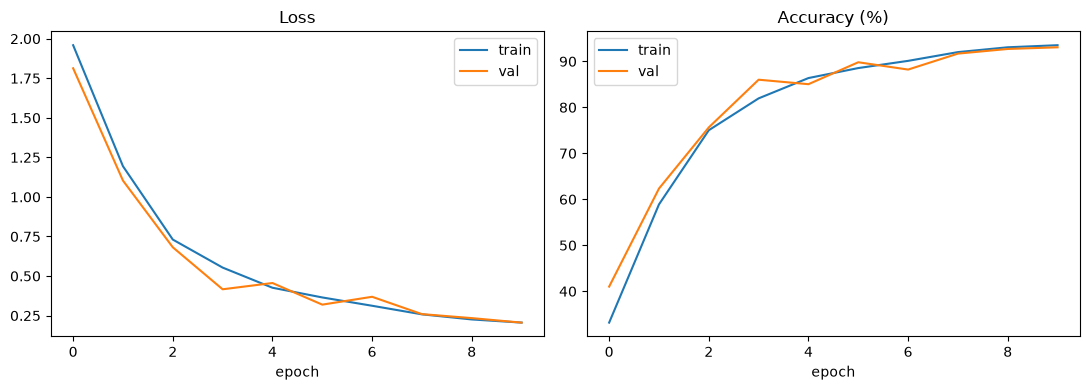

In [ ]:
# 10. Training curves
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history["train_loss"], label="train")
ax[0].plot(history["val_loss"], label="val")
ax[0].set_title("Loss")
ax[0].set_xlabel("epoch")
ax[0].legend()
ax[1].plot(history["train_acc"], label="train")
ax[1].plot(history["val_acc"], label="val")
ax[1].set_title("Accuracy (%)")
ax[1].set_xlabel("epoch")
ax[1].legend()
plt.tight_layout()
plt.show()

In [ ]:
#11. Reload best checkpoint
checkpoint = torch.load("simpsons_cnn.pth", map_location=DEVICE)
model.load_state_dict(checkpoint["state_dict"])
model.eval()
print("Loaded best model from simpsons_cnn.pth")

Loaded best model from simpsons_cnn.pth


In [30]:
# 12. Prediction helper (same preprocessing as training, RGB)
def predict_image(path, show=True):
    img = load_image_rgb(path)
    if img is None:
        raise FileNotFoundError(f"Could not read image: {path}")
 
    tensor = torch.from_numpy(img).permute(2, 0, 1).float() / 255.0
    tensor = ((tensor - 0.5) / 0.5).unsqueeze(0).to(DEVICE)   # 1 x 3 x H x W
 
    with torch.no_grad():
        probs = torch.softmax(model(tensor), dim=1)[0]
 
    top_p, top_i = probs.topk(3)
    results = [(characters[i], p.item()) for p, i in zip(top_p, top_i)]
 
    if show:
        plt.imshow(img)
        plt.axis("off")
        plt.title(f"{results[0][0]} ({results[0][1] * 100:.1f}%)")
        plt.show()
 
    return results

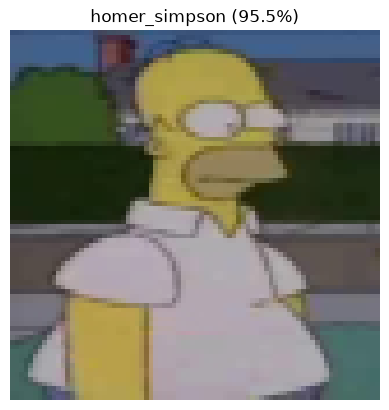

homer_simpson                95.5%
charles_montgomery_burns     1.0%
moe_szyslak                  0.9%


In [33]:
# 13.Test on a held-out validation image of a trained character
# Note: the model only knows the 10 characters above. Images of other characters
# (e.g. carl_carlson) will always be mislabelled as one of these 10.
test_character = "homer_simpson"
folder = os.path.join(DATASET_PATH, test_character)
test_path = os.path.join(folder, sorted(os.listdir(folder))[10])   # 11th image of this character
 
for name, p in predict_image(test_path):
    print(f"{name:28s} {p * 100:.1f}%")
 

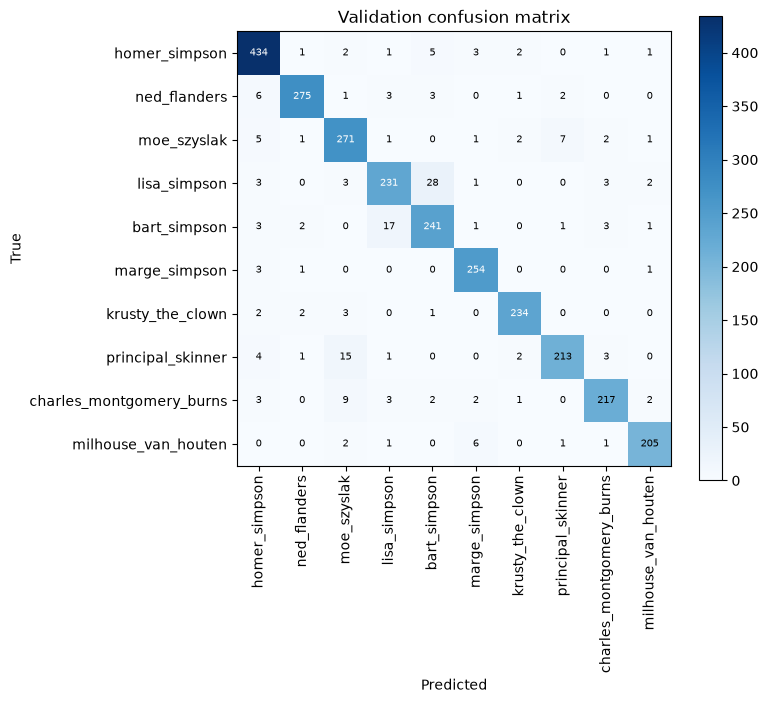

In [28]:
# 14. Confusion matrix on the validation set
all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in val_loader:
        preds = model(images.to(DEVICE)).argmax(dim=1).cpu()
        all_preds.append(preds)
        all_labels.append(labels)
 
all_preds = torch.cat(all_preds).numpy()
all_labels = torch.cat(all_labels).numpy()
 
n = len(characters)
cm = np.zeros((n, n), dtype=int)
for t, p in zip(all_labels, all_preds):
    cm[t, p] += 1
 
plt.figure(figsize=(8, 7))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(n), characters, rotation=90)
plt.yticks(range(n), characters)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Validation confusion matrix")
for i in range(n):
    for j in range(n):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=7)
plt.colorbar()
plt.tight_layout()
plt.show()
 

In [34]:
# 16. CLOSE OPENCV WINDOW
# ============================================================

cv.waitKey(0)

cv.destroyAllWindows()